# 07 — Uji Pipeline Ujung ke Ujung & Rekomendasi Pengendalian
Memakai `pipeline.py` (di folder proyek) yang merangkai: **praproses → segmentasi → rekonstruksi → fitur → SVM**.

Isi notebook:
1. **Cek konsistensi** `pipeline.py` terhadap `output/fitur.csv` (fitur dihitung ulang dari citra asli harus sama)
2. **Uji citra test** lewat jalur `pipeline.py` (harus sama dengan hasil notebook 06)
3. **Foto baru** (folder `foto_baru/`) → prediksi
4. **Rekomendasi pengendalian** per kelas
5. Simpan **`output/rekomendasi_pengendalian.json`** dan **`output/demo_prediksi/*.png`**

> Hasil test di sini hanya **verifikasi** jalur pipeline, bukan untuk tuning ulang model.

In [1]:
from pathlib import Path
import json, random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from IPython.display import display
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# Root proyek = folder pcv_bkpm (otomatis, baik dijalankan dari notebooks/ maupun root)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "dataset_crop"      # input: citra daun hasil crop, 1 subfolder = 1 kelas
OUT  = ROOT / "output"            # semua hasil notebook disimpan di sini
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
CLASSES = sorted(p.name for p in DATA.iterdir() if p.is_dir())   # label = nama subfolder

def imread(path, flags=cv2.IMREAD_COLOR):          # aman untuk path Windows ber-spasi/non-ASCII
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), flags)

def imwrite(path, img):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    ok, buf = cv2.imencode(path.suffix, img); buf.tofile(str(path)); return ok

def list_images(folder):
    return sorted(p for p in Path(folder).iterdir() if p.suffix.lower() in IMG_EXT)

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("ROOT   :", ROOT)
print("Kelas  :", CLASSES)

ROOT   : D:\SEMESTER 5\pcv
Kelas  : ['bercak_daun', 'sehat', 'ulat', 'virus_gemini']


c:\Users\Shobri\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import sys, importlib, datetime
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

sys.path.insert(0, str(ROOT))
import pipeline as P
importlib.reload(P)                      # supaya perubahan pipeline.py langsung terbaca

FOTO_BARU  = ROOT / "foto_baru"          # taruh crop daun baru di sini (atau ganti path-nya)
OUT_DEMO   = OUT / "demo_prediksi"
OUT_JSON   = OUT / "rekomendasi_pengendalian.json"
N_CHECK_PER_CLASS = 5                    # jumlah citra per kelas untuk cek konsistensi fitur
N_DEMO_TEST_PER_CLASS = 2                # jumlah demo PNG dari citra test per kelas
MARGIN_RENDAH = 0.3                      # heuristik: margin keputusan di bawah ini = "kurang yakin"

bundle = P.load_bundle()
df = pd.read_csv(OUT / "split.csv")
print("Model        :", P.MODEL_PATH.relative_to(ROOT))
print("Parameter SVM:", bundle["params"])
print("Jumlah fitur :", len(bundle["features"]), "| kelas:", bundle["label_map"])
print("Konfigurasi pipeline: SIZE =", P.SIZE, "| Gaussian =", P.GAUSS_K, "| equalisasi =", P.EQ_METHOD,
      "| open/close =", P.OPEN_K, "/", P.CLOSE_K, "| ROI =", P.ROI_FRAC)

Model        : output\model\svm_final.joblib
Parameter SVM: {'svm__C': np.float64(1.0), 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Jumlah fitur : 22 | kelas: {'bercak_daun': 0, 'sehat': 1, 'ulat': 2, 'virus_gemini': 3}
Konfigurasi pipeline: SIZE = 512 | Gaussian = (5, 5) | equalisasi = clahe | open/close = 7 / 15 | ROI = 0.4


## 1. Cek konsistensi `pipeline.py` vs `fitur.csv`

In [3]:
feat_csv = pd.read_csv(OUT / "fitur.csv")
groups = json.loads((OUT / "feature_groups.json").read_text())
csv_cols = groups["warna"] + groups["glcm"] + groups["bentuk"]

checks = {
    "Urutan 26 kolom fitur sama": csv_cols == P.FEATURE_COLS,
    "Fitur model = 22 fitur inti (urutan sama)": bundle["features"] == groups["warna"] + groups["glcm"],
    "Label map = nama subfolder dataset_crop": bundle["label_map"] == {c: i for i, c in enumerate(CLASSES)},
}
display(pd.Series(checks, name="lolos").to_frame())
assert all(checks.values()), "Struktur fitur/label tidak konsisten - cek pipeline.py dan notebook 04/06."

,lolos
Urutan 26 kolom fitur sama,True
Fitur model = 22 fitur inti (urutan sama),True
Label map = nama subfolder dataset_crop,True


In [4]:
# Hitung ulang fitur dari CITRA ASLI (dataset_crop) lewat pipeline.py, bandingkan dengan baris fitur.csv
originals = {(p.parent.name, p.stem): p for c in CLASSES for p in list_images(DATA / c)}

rng = random.Random(SEED)
rows = []
for c in CLASSES:
    sub = feat_csv[feat_csv.label_name == c]
    for _, r in sub.iloc[rng.sample(range(len(sub)), min(N_CHECK_PER_CLASS, len(sub)))].iterrows():
        stem = Path(r.path).stem
        res = P.process_image(imread(originals[(c, stem)]))
        a, b = res["fitur"], r[P.FEATURE_COLS].to_numpy(dtype=float)
        rows.append({"kelas": c, "file": stem,
                     "maks_selisih_abs": np.abs(a - b).max(),
                     "fitur_terburuk": P.FEATURE_COLS[int(np.abs(a - b).argmax())],
                     "sama": bool(np.allclose(a, b, rtol=1e-6, atol=1e-8))})
df_cons = pd.DataFrame(rows)
display(df_cons.groupby("kelas").agg(diperiksa=("file", "count"), lolos=("sama", "sum"),
                                     maks_selisih=("maks_selisih_abs", "max")))
if df_cons.sama.all():
    print(f"KONSISTEN: {len(df_cons)}/{len(df_cons)} citra menghasilkan fitur identik dengan fitur.csv.")
else:
    print(f"TIDAK KONSISTEN: {int((~df_cons.sama).sum())} citra berbeda. Biasanya karena konstanta di pipeline.py "
          "(SIZE, kernel, HSV, dll.) tidak sama dengan notebook 01-04, atau fitur.csv dibuat dengan konfigurasi lama.")
    display(df_cons[~df_cons.sama].head(10))
CONSISTENT = bool(df_cons.sama.all())

,diperiksa,lolos,maks_selisih
kelas,,,
bercak_daun,5,5,2.273737e-13
sehat,5,5,4.547474e-13
ulat,5,5,5.684342e-14
virus_gemini,5,5,2.842171e-14


KONSISTEN: 20/20 citra menghasilkan fitur identik dengan fitur.csv.


## 2. Uji citra test lewat `pipeline.py`
Tiap citra test dibaca dari **citra asli**, diproses ujung ke ujung, lalu dibandingkan dengan (a) label sebenarnya dan (b) prediksi model dari `fitur.csv` (notebook 06).

In [5]:
te = df[df.split == "test"].reset_index(drop=True)
rows = []
for _, r in tqdm(list(te.iterrows()), desc="uji test"):
    res = P.predict_image(imread(originals[(r.label_name, Path(r.path).stem)]), bundle)
    rows.append({"path": r.path, "benar": r.label_name, "prediksi": res["prediksi"], "margin": res["margin"],
                 "rasio_mask": res["rasio_mask"], "status": res["status"]})
df_te = pd.DataFrame(rows)

# prediksi model langsung dari fitur.csv (jalur notebook 06) sebagai pembanding
Xte = te[bundle["features"]]
ref = [bundle["id_to_name"][int(i)] for i in bundle["model"].predict(Xte)]
df_te["prediksi_nb06"] = ref

ok = df_te.prediksi.notna()
acc = accuracy_score(df_te.benar[ok], df_te.prediksi[ok])
f1 = f1_score(df_te.benar[ok], df_te.prediksi[ok], average="macro")
agree = float((df_te.prediksi == df_te.prediksi_nb06).mean())
print(f"Jumlah citra test: {len(df_te)} | segmentasi gagal: {int((~ok).sum())}")
print(f"Akurasi: {acc:.4f} | Macro-F1: {f1:.4f}")
print(f"Kesesuaian dengan prediksi notebook 06: {agree * 100:.1f}%")
print()
print(classification_report(df_te.benar[ok], df_te.prediksi[ok], digits=4))

uji test: 100%|██████████| 36/36 [00:08<00:00,  4.36it/s]

Jumlah citra test: 36 | segmentasi gagal: 0
Akurasi: 0.4722 | Macro-F1: 0.4519
Kesesuaian dengan prediksi notebook 06: 100.0%

              precision    recall  f1-score   support

 bercak_daun     0.4615    0.7500    0.5714         8
       sehat     0.5714    0.5714    0.5714         7
        ulat     0.1667    0.1250    0.1429         8
virus_gemini     0.6000    0.4615    0.5217        13

    accuracy                         0.4722        36
   macro avg     0.4499    0.4770    0.4519        36
weighted avg     0.4674    0.4722    0.4582        36



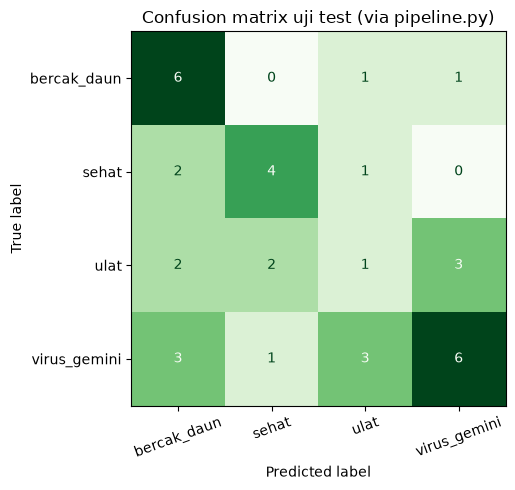

Citra test yang salah / gagal: 19


,path,benar,prediksi,margin,rasio_mask,status
0,output/03_rekonstruksi/bercak_daun/IMG_2026110...,bercak_daun,virus_gemini,1.031,0.459,ok
2,output/03_rekonstruksi/bercak_daun/IMG_2026110...,bercak_daun,ulat,1.143,0.319,ok
9,output/03_rekonstruksi/sehat/Healthy Leaf00265...,sehat,bercak_daun,1.107,0.680,ok
10,output/03_rekonstruksi/sehat/Healthy Leaf00277...,sehat,ulat,1.126,0.611,ok
11,output/03_rekonstruksi/sehat/IMG_20261108_1540...,sehat,bercak_daun,1.080,0.196,ok
15,output/03_rekonstruksi/ulat/images (3).png,ulat,bercak_daun,1.084,0.642,ok
16,output/03_rekonstruksi/ulat/IMG_20261108_16240...,ulat,bercak_daun,1.079,0.224,ok
17,output/03_rekonstruksi/ulat/IMG_20261108_16273...,ulat,virus_gemini,1.063,0.374,ok
18,output/03_rekonstruksi/ulat/IMG_20261114_07030...,ulat,virus_gemini,1.048,0.356,ok
19,output/03_rekonstruksi/ulat/IMG_20261114_07051...,ulat,virus_gemini,1.038,0.262,ok


Status segmentasi: {'ok': 35, 'periksa_segmentasi': 1}


In [6]:
cm = confusion_matrix(df_te.benar[ok], df_te.prediksi[ok], labels=CLASSES)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Greens", colorbar=False, xticks_rotation=20)
ax.set_title("Confusion matrix uji test (via pipeline.py)"); plt.tight_layout(); plt.show()

salah = df_te[df_te.benar != df_te.prediksi]
print("Citra test yang salah / gagal:", len(salah))
display(salah[["path", "benar", "prediksi", "margin", "rasio_mask", "status"]].head(10).round(3))
print("Status segmentasi:", df_te.status.value_counts().to_dict())

## 3. Foto baru
Taruh foto di folder **`foto_baru/`** (di samping `pipeline.py`). Syaratnya: foto berupa **crop satu daun** seperti isi `dataset_crop` (hasil `crop_daun_cabai.py`), bukan foto lahan utuh, karena pipeline tidak mencari daun sendiri.

In [11]:
FOTO_BARU.mkdir(exist_ok=True)
baru_files = list_images(FOTO_BARU)
print(f"Folder foto baru: {FOTO_BARU} | jumlah gambar: {len(baru_files)}")

rows, baru_res = [], {}
for p in baru_files:
    img = imread(p)
    if img is None:
        rows.append({"file": p.name, "prediksi": None, "margin": None, "rasio_mask": None, "status": "gagal_baca"}); continue
    res = P.predict_image(img, bundle)
    baru_res[p.name] = (img, res)
    yakin = None if res["margin"] is None else ("yakin" if res["margin"] >= MARGIN_RENDAH else "kurang_yakin")
    rows.append({"file": p.name, "prediksi": res["prediksi"], "margin": res["margin"],
                 "rasio_mask": res["rasio_mask"], "status": res["status"], "keyakinan": yakin})
df_baru = pd.DataFrame(rows)
if len(df_baru):
    display(df_baru.round(3))
else:
    print("Belum ada foto baru. Salin beberapa crop daun ke folder di atas lalu jalankan ulang sel ini dan sel sesudahnya.")

Folder foto baru: D:\SEMESTER 5\pcv\foto_baru | jumlah gambar: 5


,file,prediksi,margin,rasio_mask,status,keyakinan
0,3bad5551776939f8c65ab8bfef36fef0.jpg,sehat,1.439,0.386,ok,yakin
1,images (2).jpg,virus_gemini,1.183,0.685,ok,yakin
2,images (3).jpg,sehat,1.063,0.663,ok,yakin
3,images (4).jpg,ulat,1.020,0.555,ok,yakin
4,images (5).jpg,bercak_daun,1.336,0.277,ok,yakin


## 4. Rekomendasi pengendalian
Ringkasan umum berbasis prinsip **PHT (Pengendalian Hama Terpadu)**, ditulis sebagai panduan awal. Nama penyebab, bahan aktif, dan takaran tetap harus dikonfirmasi ke penyuluh (PPL/BPTP) atau dosen pembimbing, dan **ikuti label produk** yang terdaftar. Teks ini boleh kamu sesuaikan dengan referensi dari materi kuliah.

In [12]:
REKOMENDASI = {
    "sehat": {
        "nama": "Daun sehat",
        "kemungkinan_penyebab": "Tidak terdeteksi gejala penyakit atau hama pada daun ini.",
        "tingkat_perhatian": "rendah",
        "tindakan_segera": ["Tidak perlu pengendalian khusus."],
        "budidaya": ["Pemupukan berimbang dan penyiraman teratur", "Jaga sanitasi lahan (gulma, sisa tanaman)", "Pantau tanaman 2-3 kali seminggu, terutama sisi bawah daun"],
        "hayati": ["Pertahankan musuh alami; hindari penyemprotan pestisida tanpa kebutuhan"],
        "kimia": ["Tidak diperlukan."],
        "pemantauan": "Periksa ulang bila muncul bercak, daun menguning/keriting, atau lubang gigitan.",
    },
    "bercak_daun": {
        "nama": "Bercak daun",
        "kemungkinan_penyebab": "Umumnya jamur (mis. Cercospora) atau bakteri; pastikan dengan memeriksa gejala di lapangan.",
        "tingkat_perhatian": "sedang",
        "tindakan_segera": ["Petik daun bergejala berat, lalu musnahkan (bakar atau kubur), jangan dikompos",
                            "Hindari membasahi daun; siram pagi hari di pangkal tanaman",
                            "Bersihkan alat dan tangan sebelum berpindah ke tanaman sehat"],
        "budidaya": ["Perbaiki drainase dan jarak tanam agar sirkulasi udara baik", "Hindari nitrogen berlebih",
                     "Rotasi dengan tanaman non-Solanaceae", "Bersihkan gulma dan sisa tanaman terserang"],
        "hayati": ["Agens hayati (mis. Trichoderma, Bacillus) sebagai pencegahan, sesuai petunjuk produk"],
        "kimia": ["Jika serangan meluas, gunakan fungisida (atau bakterisida bila terkonfirmasi bakteri) yang terdaftar untuk cabai",
                  "Rotasi bahan aktif; patuhi dosis, interval, dan masa tunggu panen di label"],
        "pemantauan": "Amati perkembangan bercak setiap 2-3 hari; catat jumlah tanaman terserang.",
    },
    "ulat": {
        "nama": "Serangan ulat",
        "kemungkinan_penyebab": "Hama ulat pemakan daun/buah (mis. ulat grayak Spodoptera litura, penggerek Helicoverpa).",
        "tingkat_perhatian": "sedang",
        "tindakan_segera": ["Cari dan ambil ulat serta kelompok telur secara manual, lalu musnahkan",
                            "Periksa sisi bawah daun dan sekitar tanaman pada pagi atau sore hari",
                            "Buang bagian tanaman yang terserang berat"],
        "budidaya": ["Bersihkan gulma inang", "Olah tanah untuk memutus siklus pupa", "Tanam serempak dan lakukan rotasi tanaman"],
        "hayati": ["Perangkap feromon untuk memantau dan menekan ngengat dewasa",
                   "Biopestisida berbahan Bt atau virus NPV sesuai label", "Lindungi musuh alami (laba-laba, parasitoid)"],
        "kimia": ["Gunakan insektisida terdaftar hanya jika populasi melewati ambang pengendalian; pilih yang selektif",
                  "Rotasi bahan aktif untuk mencegah resistensi; ikuti label dan anjuran PPL"],
        "pemantauan": "Hitung ulat per tanaman pada sampel tanaman tiap 2-3 hari.",
    },
    "virus_gemini": {
        "nama": "Virus gemini (kuning keriting)",
        "kemungkinan_penyebab": "Begomovirus (virus gemini) yang ditularkan kutu kebul (Bemisia tabaci). Tanaman terinfeksi tidak dapat disembuhkan.",
        "tingkat_perhatian": "tinggi",
        "tindakan_segera": ["Cabut tanaman bergejala (daun menguning, keriting, kerdil), masukkan kantong, musnahkan; jangan dikompos",
                            "Periksa tanaman di sekitarnya dan kendalikan kutu kebul segera",
                            "Jangan menyentuh tanaman sehat setelah memegang tanaman sakit sebelum membersihkan tangan"],
        "budidaya": ["Gunakan bibit sehat dan, bila tersedia, varietas toleran", "Mulsa plastik perak, tanaman pembatas, perangkap kuning",
                     "Bersihkan gulma dan tanaman inang kutu kebul di sekitar lahan"],
        "hayati": ["Perangkap perekat kuning untuk memantau dan menekan kutu kebul",
                   "Jamur entomopatogen (mis. Beauveria) dan pelestarian musuh alami sesuai petunjuk produk"],
        "kimia": ["Insektisida untuk kutu kebul yang terdaftar pada fase awal, sesuai label dan anjuran PPL; ini mencegah penularan, tidak menyembuhkan tanaman terinfeksi"],
        "pemantauan": "Cek tanaman tiap 2-3 hari; catat persentase tanaman bergejala untuk keputusan pencabutan.",
    },
}
missing = [c for c in CLASSES if c not in REKOMENDASI]
print("Kelas tanpa rekomendasi:", missing if missing else "tidak ada")
display(pd.DataFrame({c: {"perhatian": REKOMENDASI[c]["tingkat_perhatian"],
                          "tindakan pertama": REKOMENDASI[c]["tindakan_segera"][0]} for c in CLASSES if c in REKOMENDASI}).T)

Kelas tanpa rekomendasi: tidak ada


,perhatian,tindakan pertama
bercak_daun,sedang,"Petik daun bergejala berat, lalu musnahkan (ba..."
sehat,rendah,Tidak perlu pengendalian khusus.
ulat,sedang,Cari dan ambil ulat serta kelompok telur secar...
virus_gemini,tinggi,"Cabut tanaman bergejala (daun menguning, kerit..."


## 5. Gambar demo prediksi → `output/demo_prediksi/*.png`

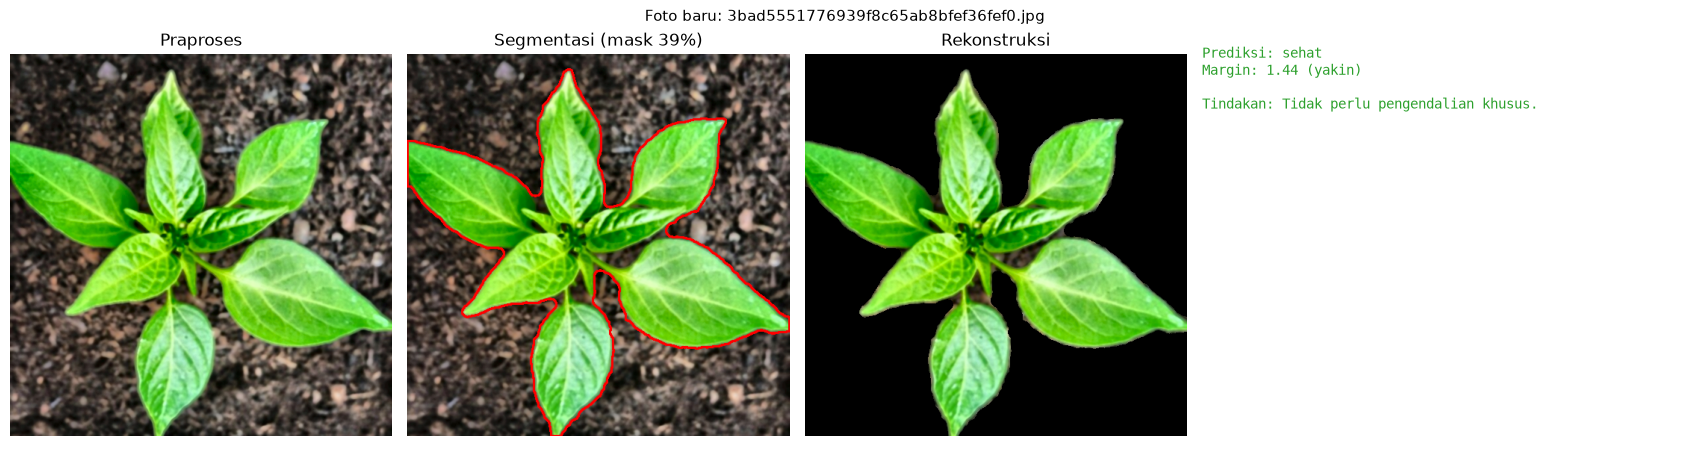

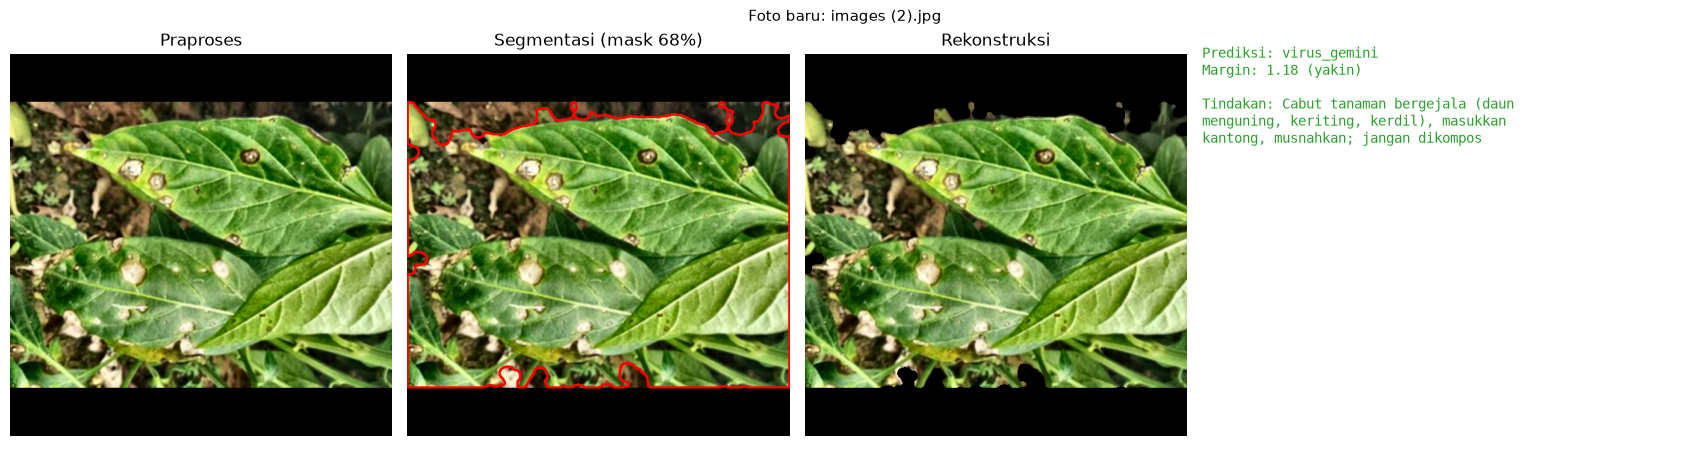

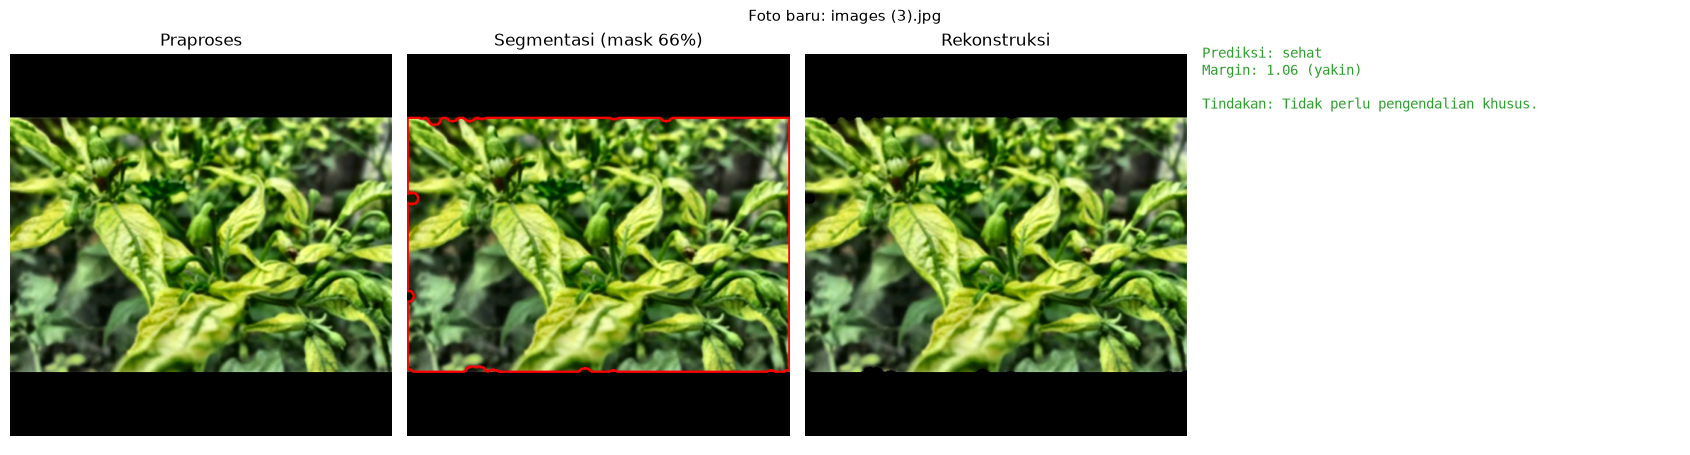

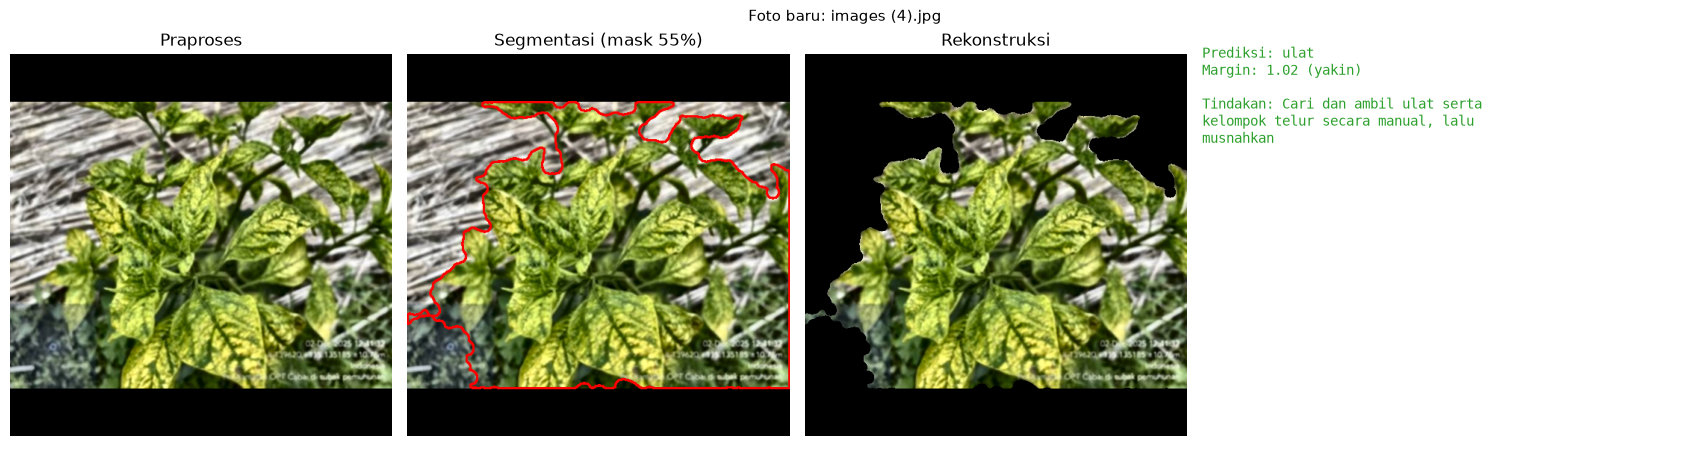

13 gambar demo tersimpan di D:\SEMESTER 5\pcv\output\demo_prediksi
['baru_3bad5551776939f8c65ab8bfef36fef0.png', 'baru_images (2).png', 'baru_images (3).png', 'baru_images (4).png', 'baru_images (5).png', 'test_bercak_daun_IMG_20261108_161643_bercak_daun_01.png', 'test_bercak_daun_IMG_20261108_160008_bercak_daun_01.png', 'test_sehat_IMG_20261114_070417_sehat_01.png'] ...


In [13]:
import textwrap

def make_demo(img, res, title, save_path, benar=None, show=False):
    pred = res["prediksi"]
    fig, axes = plt.subplots(1, 4, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.25]})
    axes[0].imshow(rgb(res["pre"])); axes[0].set_title("Praproses")
    axes[1].imshow(rgb(P.overlay(res["pre"], res["mask"]))); axes[1].set_title(f"Segmentasi (mask {res['rasio_mask'] * 100:.0f}%)")
    axes[2].imshow(rgb(res["rec"])); axes[2].set_title("Rekonstruksi")
    for a in axes[:3]: a.axis("off")
    ax = axes[3]; ax.axis("off")
    if pred is None:
        txt, color = "Segmentasi gagal\n(mask kosong).\nCek foto / threshold HSV.", "tab:red"
    else:
        rec = REKOMENDASI.get(pred, {})
        yakin = "yakin" if res["margin"] >= MARGIN_RENDAH else "KURANG YAKIN"
        head = f"Prediksi: {pred}\nMargin: {res['margin']:.2f} ({yakin})"
        if benar is not None:
            head += f"\nLabel benar: {benar}"
        body = "\n".join(textwrap.wrap("Tindakan: " + rec.get("tindakan_segera", ["-"])[0], 42))
        if res["status"] != "ok":
            body += "\n\nPERIKSA: rasio mask tidak wajar."
        txt, color = head + "\n\n" + body, ("tab:green" if benar is None or benar == pred else "tab:red")
    ax.text(0, 1, txt, va="top", fontsize=10, color=color, family="monospace")
    fig.suptitle(title, fontsize=11); plt.tight_layout()
    fig.savefig(save_path, dpi=130)
    if show: plt.show()
    plt.close(fig)

OUT_DEMO.mkdir(parents=True, exist_ok=True)
for f in OUT_DEMO.glob("*.png"): f.unlink()        # bersihkan demo lama
saved, SHOW_N = [], 4

# (a) foto baru
for name, (img, res) in baru_res.items():
    sp = OUT_DEMO / f"baru_{Path(name).stem}.png"
    make_demo(img, res, f"Foto baru: {name}", sp, show=len(saved) < SHOW_N); saved.append(sp.name)

# (b) contoh citra test (benar/salah ditandai warna)
rng = random.Random(SEED)
for c in CLASSES:
    sub = df_te[(df_te.benar == c)]
    for _, r in sub.iloc[rng.sample(range(len(sub)), min(N_DEMO_TEST_PER_CLASS, len(sub)))].iterrows():
        img = imread(originals[(c, Path(r.path).stem)])
        res = P.predict_image(img, bundle)
        sp = OUT_DEMO / f"test_{c}_{Path(r.path).stem}.png"
        make_demo(img, res, f"Uji test: {c}/{Path(r.path).stem}", sp, benar=c, show=len(saved) < SHOW_N); saved.append(sp.name)

print(f"{len(saved)} gambar demo tersimpan di {OUT_DEMO}")
print(saved[:8], "..." if len(saved) > 8 else "")

## 6. Simpan `rekomendasi_pengendalian.json`

In [15]:
def _f(x):
    return None if x is None or (isinstance(x, float) and np.isnan(x)) else round(float(x), 4)

hasil_baru = []
for _, r in df_baru.iterrows():
    rec = REKOMENDASI.get(r.prediksi) if r.prediksi else None
    hasil_baru.append({
        "file": r.file, "prediksi": r.prediksi, "margin_keputusan": _f(r.margin), "rasio_mask": _f(r.rasio_mask),
        "status_segmentasi": r.status, "keyakinan": r.get("keyakinan"),
        "rekomendasi": rec,
        "gambar_demo": f"output/demo_prediksi/baru_{Path(r.file).stem}.png" if r.prediksi else None,
    })

payload = {
    "dibuat": datetime.datetime.now().isoformat(timespec="seconds"),
    "catatan": ("Keluaran model adalah alat bantu. Konfirmasi gejala di lapangan dan konsultasikan pengendalian "
                "(terutama bahan kimia dan takaran) ke penyuluh/PPL atau pakar; ikuti label produk terdaftar."),
    "model": {"file": P.MODEL_PATH.relative_to(ROOT).as_posix(), "parameter": {k: str(v) for k, v in bundle["params"].items()},
              "jumlah_fitur": len(bundle["features"]), "kelas": CLASSES},
    "uji_pipeline": {"konsisten_dengan_fitur_csv": CONSISTENT, "citra_test": int(len(df_te)),
                     "akurasi_test": _f(acc), "macro_f1_test": _f(f1), "kesesuaian_dengan_notebook_06_persen": _f(agree * 100)},
    "panduan_per_kelas": {c: REKOMENDASI[c] for c in CLASSES if c in REKOMENDASI},
    "prediksi_foto_baru": hasil_baru,
}
OUT_JSON.write_text(json.dumps(payload, indent=2, ensure_ascii=False), encoding="utf-8")
print("Tersimpan:", OUT_JSON, f"({OUT_JSON.stat().st_size / 1024:.1f} KB)")
print(json.dumps({k: payload[k] for k in ["model", "uji_pipeline"]}, indent=2, ensure_ascii=False))
print("Prediksi foto baru:", [(h["file"], h["prediksi"]) for h in hasil_baru] or "belum ada")

Tersimpan: D:\SEMESTER 5\pcv\output\rekomendasi_pengendalian.json (11.8 KB)
{
  "model": {
    "file": "output/model/svm_final.joblib",
    "parameter": {
      "svm__C": "1.0",
      "svm__gamma": "scale",
      "svm__kernel": "rbf"
    },
    "jumlah_fitur": 22,
    "kelas": [
      "bercak_daun",
      "sehat",
      "ulat",
      "virus_gemini"
    ]
  },
  "uji_pipeline": {
    "konsisten_dengan_fitur_csv": true,
    "citra_test": 36,
    "akurasi_test": 0.4722,
    "macro_f1_test": 0.4519,
    "kesesuaian_dengan_notebook_06_persen": 100.0
  }
}
Prediksi foto baru: [('3bad5551776939f8c65ab8bfef36fef0.jpg', 'sehat'), ('images (2).jpg', 'virus_gemini'), ('images (3).jpg', 'sehat'), ('images (4).jpg', 'ulat'), ('images (5).jpg', 'bercak_daun')]
